# Tugas Praktikum - Klasifikasi Angka Tulisan Tangan (MNIST) dengan JST

Notebook ini membangun Jaringan Saraf Tiruan (JST) menggunakan Keras/TensorFlow untuk
mengklasifikasikan angka tulisan tangan pada dataset **MNIST**.

**Yang dilakukan:**
1. Load dataset MNIST dari Keras.
2. Membangun model dengan **2 hidden layer**.
3. Melatih dan mengevaluasi akurasi.
4. Eksperimen: variasi jumlah neuron, tambahan hidden layer, serta **Sigmoid vs ReLU**.
5. Membandingkan **akurasi** dan **waktu pelatihan**.

Setiap konfigurasi dijalankan dengan **3 seed** agar hasil lebih stabil dan dapat
dibandingkan secara adil.

## Langkah 1 - Import Library

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Input
from tensorflow.keras.utils import to_categorical

%matplotlib inline
RANDOM_STATE = 42
SEEDS = [42, 7, 123]
EPOCHS = 10
BATCH_SIZE = 128

tf.get_logger().setLevel('ERROR')
print('TensorFlow:', tf.__version__)

TensorFlow: 2.20.0


## Langkah 2 - Load Dataset MNIST

In [2]:
# Load dataset MNIST
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Simpan label asli untuk visualisasi dan distribusi kelas
y_train_labels = y_train.copy()
y_test_labels = y_test.copy()

# Normalisasi data (0-255 -> 0-1)
X_train = X_train / 255.0
X_test = X_test / 255.0

# One-hot encoding label
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

print('X_train:', X_train.shape, '| X_test:', X_test.shape)
print('y_train:', y_train.shape, '| y_test:', y_test.shape)
print('Rentang piksel:', X_train.min(), '-', X_train.max())
print('Distribusi kelas data latih:', np.bincount(y_train_labels))

X_train: (60000, 28, 28) | X_test: (10000, 28, 28)
y_train: (60000, 10) | y_test: (10000, 10)
Rentang piksel: 0.0 - 1.0
Distribusi kelas data latih: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


### Visualisasi Contoh Data

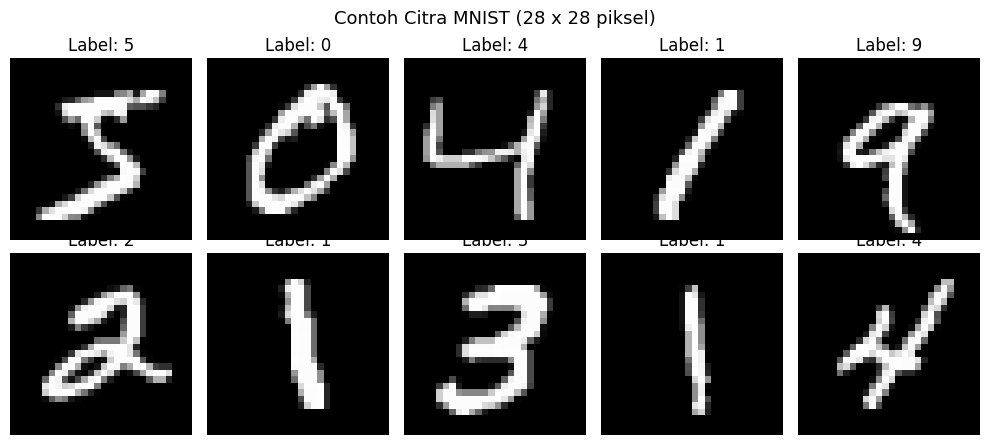

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))

for i, ax in enumerate(axes.ravel()):
    ax.imshow(X_train[i], cmap='gray')
    ax.set_title(f'Label: {y_train_labels[i]}')
    ax.axis('off')

plt.suptitle('Contoh Citra MNIST (28 x 28 piksel)', fontsize=13)
plt.tight_layout()
plt.show()

## Langkah 3 - Fungsi Pembangun dan Pelatih Model

Fungsi `train_mnist` membangun model MLP, melatihnya, mengukur **waktu pelatihan**
(hanya proses `fit`), lalu mengevaluasi akurasi pada data uji.

In [4]:
def build_model(hidden_units=(128, 64), activation='relu', seed=RANDOM_STATE):
    tf.keras.utils.set_random_seed(seed)

    layers = [Input(shape=(28, 28)), Flatten()]
    for units in hidden_units:
        layers.append(Dense(units, activation=activation))
    layers.append(Dense(10, activation='softmax'))

    model = Sequential(layers)
    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model


def train_mnist(hidden_units=(128, 64), activation='relu', seed=RANDOM_STATE,
                epochs=EPOCHS, batch_size=BATCH_SIZE):
    model = build_model(hidden_units, activation, seed)

    start = time.perf_counter()
    history = model.fit(
        X_train, y_train,
        epochs=epochs,
        batch_size=batch_size,
        verbose=0
    )
    train_time = time.perf_counter() - start

    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)

    return model, history, {
        'Test Accuracy': test_acc,
        'Test Loss': test_loss,
        'Training Time (s)': train_time,
        'Parameters': model.count_params(),
    }

## Langkah 4 - Model Awal: 2 Hidden Layer (128 - 64, ReLU)

Arsitektur: Flatten(28x28) -> Dense(128, ReLU) -> Dense(64, ReLU) -> Dense(10, Softmax).

In [5]:
model_awal, history_awal, metrics_awal = train_mnist(
    hidden_units=(128, 64), activation='relu', seed=RANDOM_STATE
)

model_awal.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 328,160 (1.25 MB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 218,774 (854.59 KB)

In [6]:
loss, acc = model_awal.evaluate(X_test, y_test, verbose=0)
print(f'Akurasi pada data uji: {acc:.4f}')
print(f'Loss pada data uji   : {loss:.4f}')
print(f'Waktu pelatihan      : {metrics_awal["Training Time (s)"]:.2f} detik')
print(f'Jumlah parameter     : {metrics_awal["Parameters"]:,}')

Akurasi pada data uji: 0.9749
Loss pada data uji   : 0.0950
Waktu pelatihan      : 4.40 detik
Jumlah parameter     : 109,386


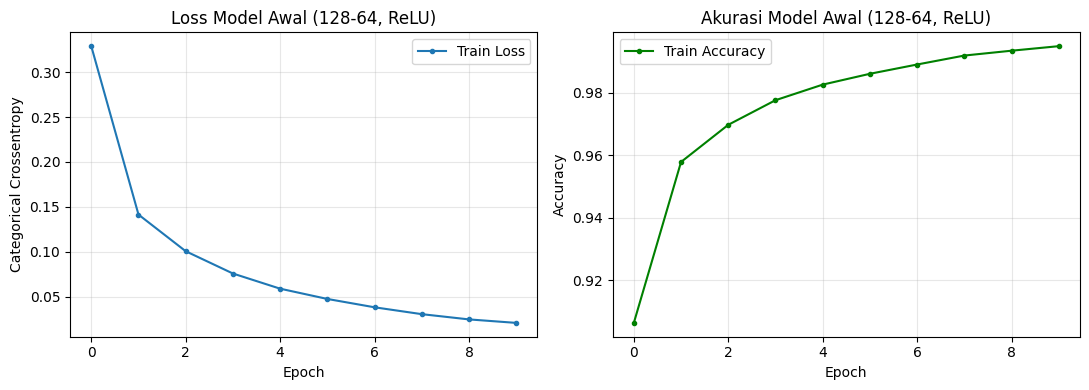

In [7]:
# Kurva pembelajaran model awal
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(history_awal.history['loss'], marker='o', markersize=3, label='Train Loss')
axes[0].set_title('Loss Model Awal (128-64, ReLU)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Categorical Crossentropy')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history_awal.history['accuracy'], marker='o', markersize=3,
             color='green', label='Train Accuracy')
axes[1].set_title('Akurasi Model Awal (128-64, ReLU)')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Langkah 5 - Eksperimen

Seluruh konfigurasi berikut dilatih dengan pengaturan yang sama:
**10 epoch**, **batch size 128**, optimizer Adam, loss categorical crossentropy.
Setiap konfigurasi dijalankan dengan 3 seed (42, 7, 123).

Konfigurasi yang diuji:

| Label | Hidden Layer | Aktivasi | Keterangan |
|-------|--------------|----------|------------|
| 64-32 | 64, 32 | ReLU | lebih kecil |
| 128-64 | 128, 64 | ReLU | model awal |
| 256-128 | 256, 128 | ReLU | lebih besar (contoh modul) |
| 256-128-64 | 256, 128, 64 | ReLU | tambah 1 hidden layer |
| 256-128 sigmoid | 256, 128 | Sigmoid | perbandingan aktivasi |

In [8]:
configs = [
    ('64-32', (64, 32), 'relu'),
    ('128-64', (128, 64), 'relu'),
    ('256-128', (256, 128), 'relu'),
    ('256-128-64', (256, 128, 64), 'relu'),
    ('256-128 sigmoid', (256, 128), 'sigmoid'),
]

rows = []
histories = {}

for label, units, act in configs:
    for seed in SEEDS:
        model, history, metrics = train_mnist(
            hidden_units=units, activation=act, seed=seed,
            epochs=EPOCHS, batch_size=BATCH_SIZE
        )
        rows.append({
            'Konfigurasi': label,
            'Hidden Layer': '-'.join(map(str, units)),
            'Aktivasi': act,
            'Seed': seed,
            **metrics,
            'Train Acc Epoch 1': history.history['accuracy'][0],
        })
        histories[(label, seed)] = history.history

    print(f'Selesai: {label}')

df_results = pd.DataFrame(rows)
df_results.head(8)

Selesai: 64-32


Selesai: 128-64


Selesai: 256-128


Selesai: 256-128-64


Selesai: 256-128 sigmoid


,Konfigurasi,Hidden Layer,Aktivasi,Seed,Test Accuracy,Test Loss,Training Time (s),Parameters,Train Acc Epoch 1
0,64-32,64-32,relu,42,0.9720,0.093028,3.138343,52650,0.882850
1,64-32,64-32,relu,7,0.9704,0.099132,3.186421,52650,0.886900
2,64-32,64-32,relu,123,0.9724,0.092951,3.141784,52650,0.883617
3,128-64,128-64,relu,42,0.9749,0.095025,4.477779,109386,0.906333
4,128-64,128-64,relu,7,0.9766,0.088182,4.520171,109386,0.907350
5,128-64,128-64,relu,123,0.9737,0.094040,4.598623,109386,0.905583
6,256-128,256-128,relu,42,0.9775,0.085439,6.584391,235146,0.921950
7,256-128,256-128,relu,7,0.9807,0.078774,6.604157,235146,0.923100


In [9]:
order = [label for label, _, _ in configs]

summary_rows = []
for label in order:
    sub = df_results[df_results['Konfigurasi'] == label]
    summary_rows.append({
        'Konfigurasi': label,
        'Aktivasi': sub['Aktivasi'].iloc[0],
        'Parameter': int(sub['Parameters'].iloc[0]),
        'Test Accuracy': f"{sub['Test Accuracy'].mean():.4f} ± {sub['Test Accuracy'].std():.4f}",
        'Training Time (s)': f"{sub['Training Time (s)'].mean():.2f} ± {sub['Training Time (s)'].std():.2f}",
        'Train Acc Epoch 1': f"{sub['Train Acc Epoch 1'].mean():.4f}",
    })

summary_all = pd.DataFrame(summary_rows)
summary_all

,Konfigurasi,Aktivasi,Parameter,Test Accuracy,Training Time (s),Train Acc Epoch 1
0,64-32,relu,52650,0.9716 ± 0.0011,3.16 ± 0.03,0.8845
1,128-64,relu,109386,0.9751 ± 0.0015,4.53 ± 0.06,0.9064
2,256-128,relu,235146,0.9771 ± 0.0039,6.63 ± 0.06,0.9225
3,256-128-64,relu,242762,0.9778 ± 0.0009,7.48 ± 0.06,0.9190
4,256-128 sigmoid,sigmoid,235146,0.9767 ± 0.0005,7.43 ± 0.11,0.8447


### Eksperimen 1 - Variasi Jumlah Neuron Hidden Layer

In [10]:
neuron_labels = ['64-32', '128-64', '256-128']
summary_neuron = summary_all[summary_all['Konfigurasi'].isin(neuron_labels)].reset_index(drop=True)
summary_neuron

,Konfigurasi,Aktivasi,Parameter,Test Accuracy,Training Time (s),Train Acc Epoch 1
0,64-32,relu,52650,0.9716 ± 0.0011,3.16 ± 0.03,0.8845
1,128-64,relu,109386,0.9751 ± 0.0015,4.53 ± 0.06,0.9064
2,256-128,relu,235146,0.9771 ± 0.0039,6.63 ± 0.06,0.9225


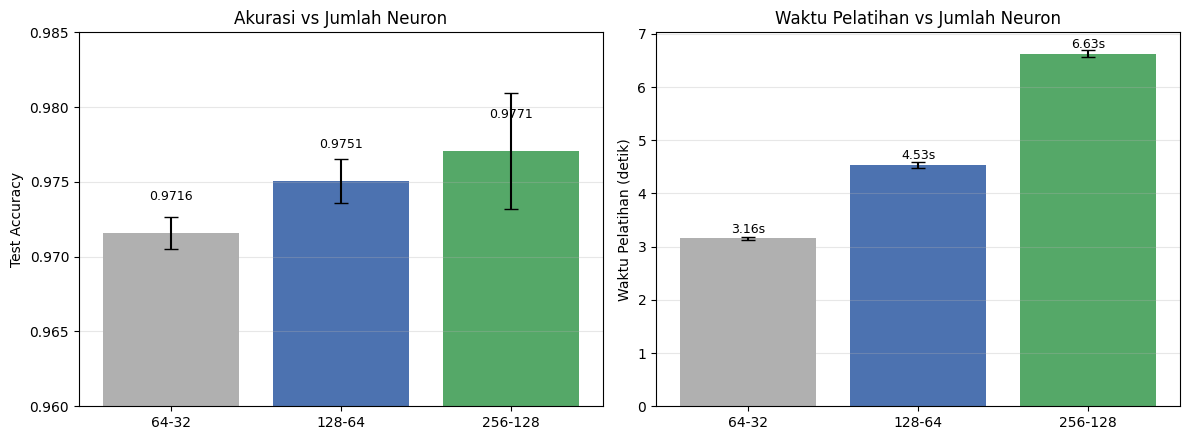

In [11]:
# Grafik akurasi dan waktu pelatihan
mean_acc = df_results.groupby('Konfigurasi')['Test Accuracy'].mean().reindex(neuron_labels)
std_acc = df_results.groupby('Konfigurasi')['Test Accuracy'].std().reindex(neuron_labels)
mean_time = df_results.groupby('Konfigurasi')['Training Time (s)'].mean().reindex(neuron_labels)
std_time = df_results.groupby('Konfigurasi')['Training Time (s)'].std().reindex(neuron_labels)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

bars = axes[0].bar(mean_acc.index, mean_acc.values, yerr=std_acc.values,
                   capsize=5, color=['#b0b0b0', '#4c72b0', '#55a868'])
for bar, value in zip(bars, mean_acc.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
                 f'{value:.4f}', ha='center', va='bottom', fontsize=9)
axes[0].set_ylim(0.96, 0.985)
axes[0].set_ylabel('Test Accuracy')
axes[0].set_title('Akurasi vs Jumlah Neuron')
axes[0].grid(axis='y', alpha=0.3)

bars = axes[1].bar(mean_time.index, mean_time.values, yerr=std_time.values,
                   capsize=5, color=['#b0b0b0', '#4c72b0', '#55a868'])
for bar, value in zip(bars, mean_time.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
                 f'{value:.2f}s', ha='center', va='bottom', fontsize=9)
axes[1].set_ylabel('Waktu Pelatihan (detik)')
axes[1].set_title('Waktu Pelatihan vs Jumlah Neuron')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### Eksperimen 2 - Menambah Satu Hidden Layer (256-128 vs 256-128-64)

In [12]:
layer_labels = ['256-128', '256-128-64']
summary_layers = summary_all[summary_all['Konfigurasi'].isin(layer_labels)].reset_index(drop=True)
summary_layers

,Konfigurasi,Aktivasi,Parameter,Test Accuracy,Training Time (s),Train Acc Epoch 1
0,256-128,relu,235146,0.9771 ± 0.0039,6.63 ± 0.06,0.9225
1,256-128-64,relu,242762,0.9778 ± 0.0009,7.48 ± 0.06,0.9190


### Eksperimen 3 - Sigmoid vs ReLU (arsitektur 256-128)

In [13]:
activation_labels = ['256-128', '256-128 sigmoid']
summary_activation = summary_all[summary_all['Konfigurasi'].isin(activation_labels)].reset_index(drop=True)
summary_activation

,Konfigurasi,Aktivasi,Parameter,Test Accuracy,Training Time (s),Train Acc Epoch 1
0,256-128,relu,235146,0.9771 ± 0.0039,6.63 ± 0.06,0.9225
1,256-128 sigmoid,sigmoid,235146,0.9767 ± 0.0005,7.43 ± 0.11,0.8447


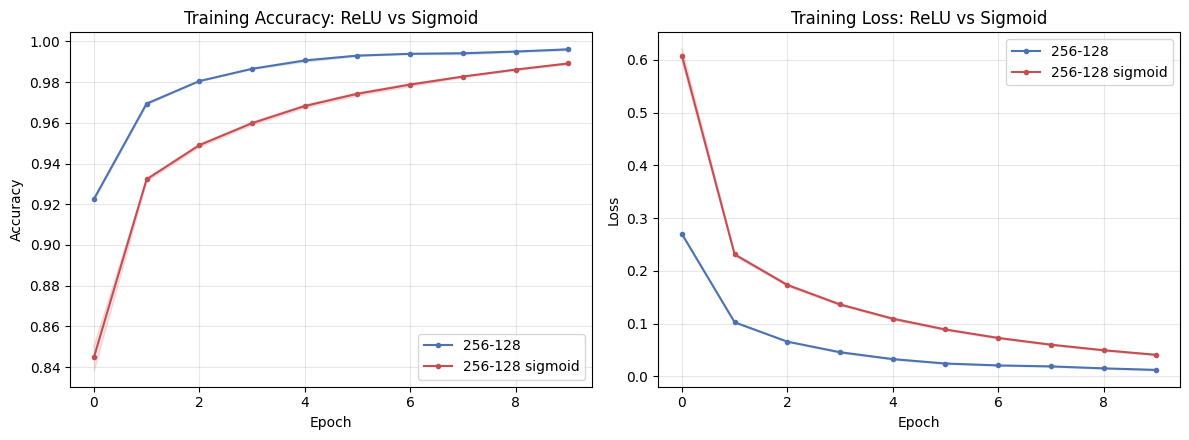

In [14]:
# Kurva konvergensi rata-rata: ReLU vs Sigmoid
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for label, color in [('256-128', '#4c72b0'), ('256-128 sigmoid', '#c44e52')]:
    acc_hist = np.array([histories[(label, seed)]['accuracy'] for seed in SEEDS])
    loss_hist = np.array([histories[(label, seed)]['loss'] for seed in SEEDS])
    epoch_axis = np.arange(acc_hist.shape[1])

    acc_mean, acc_std = acc_hist.mean(axis=0), acc_hist.std(axis=0)
    loss_mean, loss_std = loss_hist.mean(axis=0), loss_hist.std(axis=0)

    axes[0].plot(epoch_axis, acc_mean, marker='o', markersize=3, label=label, color=color)
    axes[0].fill_between(epoch_axis, acc_mean - acc_std, acc_mean + acc_std,
                         alpha=0.15, color=color)

    axes[1].plot(epoch_axis, loss_mean, marker='o', markersize=3, label=label, color=color)
    axes[1].fill_between(epoch_axis, loss_mean - loss_std, loss_mean + loss_std,
                         alpha=0.15, color=color)

axes[0].set_title('Training Accuracy: ReLU vs Sigmoid')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title('Training Loss: ReLU vs Sigmoid')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Analisis

**1. Pengaruh jumlah neuron hidden layer:**
- Konfigurasi 64-32 memiliki akurasi terendah dan waktu pelatihan paling singkat.
- Menambah neuron menjadi 128-64 dan 256-128 meningkatkan akurasi, tetapi kenaikannya
  semakin kecil (*diminishing return*), sementara waktu pelatihan terus bertambah.
- Untuk MNIST, konfigurasi 256-128 memberikan akurasi tinggi dengan waktu yang masih wajar.

**2. Pengaruh tambahan hidden layer:**
- Menambah hidden layer ketiga (256-128-64) hanya menaikkan akurasi sangat sedikit
  dibanding 256-128, dengan waktu pelatihan yang lebih lama.
- Pada data gambar, peningkatan performa yang lebih besar biasanya diperoleh dengan
  Convolutional Neural Network (CNN), bukan sekadar menambah layer Dense.

**3. Sigmoid vs ReLU:**
- Akurasi akhir keduanya hampir sama pada 10 epoch dengan optimizer Adam.
- Namun ReLU **konvergen jauh lebih cepat**: akurasi training epoch pertama ReLU sekitar
  0.92, sedangkan Sigmoid sekitar 0.84.
- Sigmoid lebih rentan terhadap *vanishing gradient* karena turunannya mengecil pada
  nilai ekstrem, sehingga pembelajaran pada layer terdalam menjadi lebih lambat.

**Catatan:** Waktu pelatihan diukur di CPU dan dapat berbeda antar perangkat. Karena itu
perbandingan waktu bersifat relatif terhadap mesin yang sama. Setiap konfigurasi diuji
dengan 3 seed dan dilaporkan sebagai rata-rata ± standar deviasi.

## Kesimpulan

In [15]:
print('=== Ringkasan Semua Konfigurasi ===')
print(summary_all.to_string(index=False))

best_row = df_results.groupby('Konfigurasi')['Test Accuracy'].mean().idxmax()
best_acc = df_results.groupby('Konfigurasi')['Test Accuracy'].mean().max()
print(f'\nAkurasi rata-rata tertinggi: {best_row} ({best_acc:.4f})')

=== Ringkasan Semua Konfigurasi ===
    Konfigurasi Aktivasi  Parameter   Test Accuracy Training Time (s) Train Acc Epoch 1
          64-32     relu      52650 0.9716 ± 0.0011       3.16 ± 0.03            0.8845
         128-64     relu     109386 0.9751 ± 0.0015       4.53 ± 0.06            0.9064
        256-128     relu     235146 0.9771 ± 0.0039       6.63 ± 0.06            0.9225
     256-128-64     relu     242762 0.9778 ± 0.0009       7.48 ± 0.06            0.9190
256-128 sigmoid  sigmoid     235146 0.9767 ± 0.0005       7.43 ± 0.11            0.8447

Akurasi rata-rata tertinggi: 256-128-64 (0.9778)
